In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import pandas as pd
import numpy as np
data = pd.read_csv('/kaggle/input/datasets/rajlaxmikasture/customer-data/customer_data.csv')

In [3]:
data.head()

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    object 
 3   Location          100 non-null    object 
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 5.6+ KB


In [5]:
data.describe()

,CustomerID,Age,TotalPurchases,TotalAmountSpent
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,45.090000,16.620000,2494.188400
std,29.011492,15.814643,9.032802,1471.248513
min,1.000000,18.000000,1.000000,57.640000
25%,25.750000,31.000000,9.750000,1112.405000
50%,50.500000,45.500000,15.000000,2626.165000
75%,75.250000,60.000000,26.000000,3812.867500
max,100.000000,70.000000,30.000000,4966.480000


In [6]:
data.isnull().sum()

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64

In [7]:
data.shape

(100, 7)

In [8]:
data.columns

Index(['CustomerID', 'Age', 'Gender', 'Location', 'TotalPurchases',
       'TotalAmountSpent', 'LastPurchaseDate'],
      dtype='object')

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
#calculate csv(cusomer lifetime value = average purchase * purcahse frequency)
#purchase frequency--it is simply the number of purchases made by each customer
data["AveragePurchase"] = (
    data["TotalAmountSpent"]/data["TotalPurchases"]
)

data[["CustomerID","AveragePurchase"]].head()

,CustomerID,AveragePurchase
0,1,24.796250
1,2,100.054138
2,3,216.313158
3,4,86.101852
4,5,74.844667


In [11]:
data["clv"] = data["AveragePurchase"] * data["TotalPurchases"]
data.head()

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AveragePurchase,clv
0,1,68,Female,Houston,24,595.11,2023-01-01,24.796250,595.11
1,2,35,Male,Phoenix,29,2901.57,2023-01-08,100.054138,2901.57
2,3,60,Male,Phoenix,19,4109.95,2023-01-15,216.313158,4109.95
3,4,63,Female,Chicago,27,2324.75,2023-01-22,86.101852,2324.75
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29,74.844667,1122.67


In [12]:
#problem statement 1
# who their most valuable customers are.
top_customers = (
    data.sort_values(by="TotalAmountSpent",ascending=False).head(10)
)
top_customers[[
    "CustomerID",
    "TotalAmountSpent",
    "TotalPurchases",
    "Age",
    "Gender",
    "Location"
]]

,CustomerID,TotalAmountSpent,TotalPurchases,Age,Gender,Location
97,98,4966.48,7,60,Male,Houston
38,39,4947.37,5,18,Female,Phoenix
44,45,4880.54,11,69,Female,Houston
42,43,4835.52,15,66,Female,Houston
40,41,4785.73,12,20,Female,Phoenix
78,79,4766.31,30,43,Male,Chicago
63,64,4532.50,10,57,Male,Houston
33,34,4467.34,28,43,Female,Chicago
87,88,4380.05,9,49,Female,Houston
23,24,4302.12,8,31,Male,Los Angeles


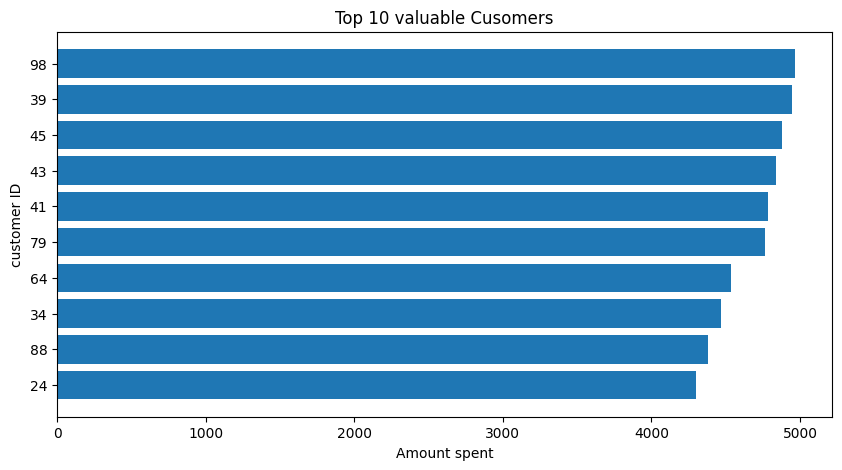

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))

plt.barh(top_customers['CustomerID'].astype(str),
        top_customers['TotalAmountSpent'])
plt.xlabel("Amount spent")
plt.ylabel("customer ID")
plt.title("Top 10 valuable Cusomers")

#Highest spender at the top
plt.gca().invert_yaxis()

plt.show()

In [14]:
#problem statement2
#what demographic group spends the most
#which gender spends more
gender_spending = data.groupby("Gender")["TotalAmountSpent"].mean()
gender_spending

Gender
Female    2263.2020
Male      2725.1748
Name: TotalAmountSpent, dtype: float64

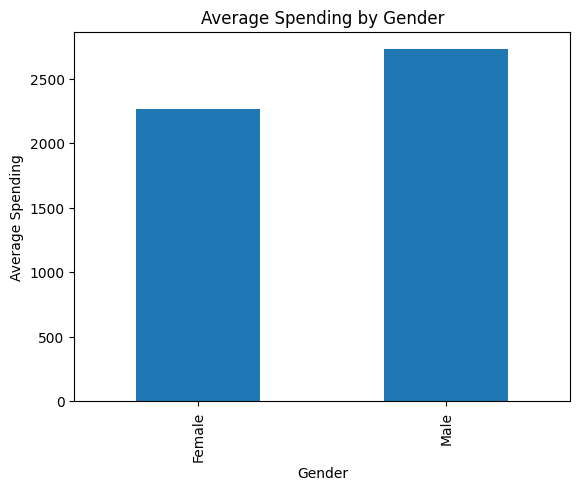

In [15]:
gender_spending.plot(kind='bar')
plt.ylabel("Average Spending")
plt.title("Average Spending by Gender")
plt.title("Average Spending by Gender")
plt.show()

In [17]:
#which age group spends the most
bins = [1,25,35,45,55,65,100]
labels=[
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "65+"
]
data["agegroup"]=pd.cut(data["Age"],
                       bins=bins,
                       labels=labels)

In [18]:
age_spending = data.groupby("agegroup")["TotalAmountSpent"].mean()
age_spending

/tmp/ipykernel_58/3192936901.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_spending = data.groupby("agegroup")["TotalAmountSpent"].mean()


agegroup
18-25    2470.107143
26-35    2702.492632
36-45    2282.241765
46-55    1945.067647
56-65    2866.600476
65+      2618.925833
Name: TotalAmountSpent, dtype: float64

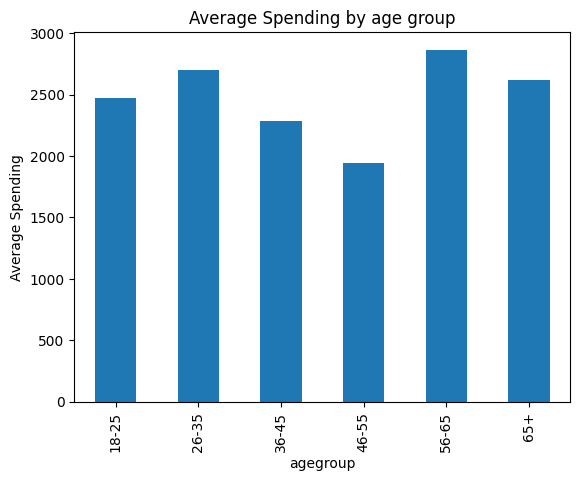

In [19]:
age_spending.plot(kind="bar")
plt.ylabel("Average Spending")
plt.title("Average Spending by age group")
plt.show()

In [20]:
#which city/location has highest spending
data.head()
city_spending = data.groupby("Location")["TotalAmountSpent"].mean()
city_spending = city_spending.sort_values(ascending=False)
city_spending

Location
Phoenix        2855.443333
Chicago        2583.337222
Houston        2515.688125
Los Angeles    2217.375714
New York       2093.945333
Name: TotalAmountSpent, dtype: float64

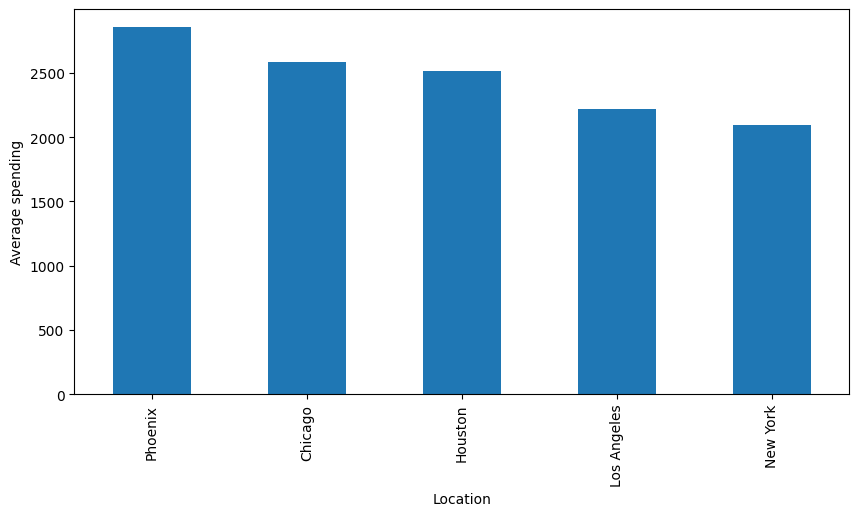

In [55]:
import matplotlib.pyplot as plt
city_spending.head(10).plot(kind="bar",figsize=(10,5))
plt.ylabel("Average spending")
plt.show()

In [21]:
#problem statement
#How purchase patterns differ by age, gender, and location.
#average purchase by gender
data.groupby("Gender")["TotalPurchases"].mean()


Gender
Female    17.10
Male      16.14
Name: TotalPurchases, dtype: float64

In [22]:
# average purchase by age
data.groupby("agegroup")["TotalPurchases"].mean()

/tmp/ipykernel_58/1803476974.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("agegroup")["TotalPurchases"].mean()


agegroup
18-25    15.142857
26-35    17.842105
36-45    19.176471
46-55    14.823529
56-65    16.619048
65+      15.333333
Name: TotalPurchases, dtype: float64

In [23]:
#average purchase by location
data.groupby("Location")["TotalPurchases"].mean().sort_values(ascending=False)


Location
Chicago        19.111111
Phoenix        16.571429
Los Angeles    16.500000
Houston        16.312500
New York       14.466667
Name: TotalPurchases, dtype: float64

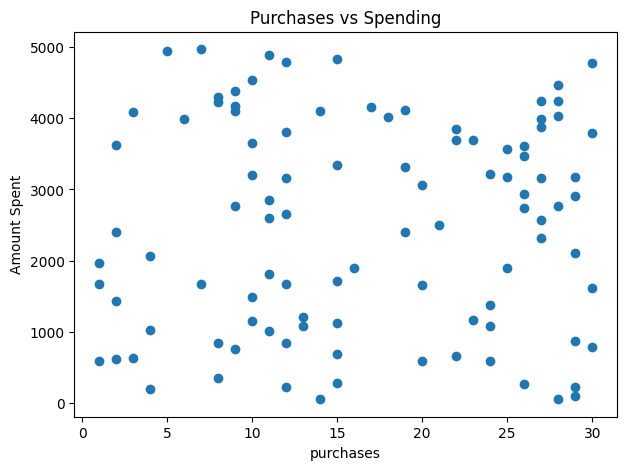

In [24]:
#spending vs purchases
plt.figure(figsize=(7,5))
plt.scatter(data["TotalPurchases"],
           data["TotalAmountSpent"])
plt.xlabel("purchases")
plt.ylabel("Amount Spent")
plt.title("Purchases vs Spending")
plt.show()

/tmp/ipykernel_58/1725187961.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = data.pivot_table(values="TotalAmountSpent",


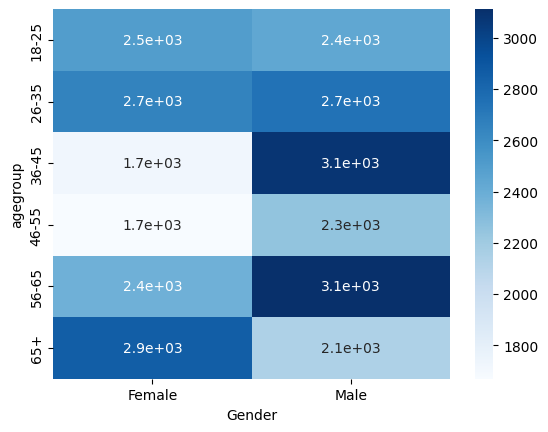

In [25]:
#Heatmap
import seaborn as sns
pivot = data.pivot_table(values="TotalAmountSpent",
                       index="agegroup",
                       columns="Gender",
                       aggfunc="mean")
sns.heatmap(pivot,
           annot =True,
           cmap="Blues")
plt.show()

In [28]:
# problem statement 4
#Potential target groups for marketing campaigns.
#possible target groups
#Premimum Customers
#Frequent Buyers
#Young Customers
#Senior Customers
#high Revenue Locations
high_spenders = data[
data["TotalAmountSpent"]>
data["TotalAmountSpent"].quantile(.75)
]
high_spenders.head()

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AveragePurchase,clv,agegroup
2,3,60,Male,Phoenix,19,4109.95,2023-01-15,216.313158,4109.95,56-65
6,7,60,Male,Phoenix,28,4032.94,2023-02-12,144.033571,4032.94,56-65
12,13,26,Female,Houston,22,3846.73,2023-03-26,174.851364,3846.73,26-35
13,14,34,Male,Houston,28,4241.34,2023-04-02,151.476429,4241.34,26-35
15,16,50,Male,New York,27,3873.24,2023-04-16,143.453333,3873.24,46-55


In [31]:
#Frequent_buyers=
data[
data["TotalPurchases"]>
data["TotalPurchases"].quantile(.75)
]


,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AveragePurchase,clv,agegroup
1,2,35,Male,Phoenix,29,2901.57,2023-01-08,100.054138,2901.57,26-35
3,4,63,Female,Chicago,27,2324.75,2023-01-22,86.101852,2324.75,56-65
6,7,60,Male,Phoenix,28,4032.94,2023-02-12,144.033571,4032.94,56-65
10,11,21,Female,Los Angeles,30,1621.33,2023-03-12,54.044333,1621.33,18-25
13,14,34,Male,Houston,28,4241.34,2023-04-02,151.476429,4241.34,26-35
15,16,50,Male,New York,27,3873.24,2023-04-16,143.453333,3873.24,46-55
17,18,42,Male,Houston,30,3788.89,2023-04-30,126.296333,3788.89,36-45
22,23,49,Male,Houston,27,3153.45,2023-06-04,116.794444,3153.45,46-55
33,34,43,Female,Chicago,28,4467.34,2023-08-20,159.547857,4467.34,36-45
34,35,43,Female,Phoenix,29,2115.42,2023-08-27,72.945517,2115.42,36-45


In [34]:
senior = data[data["Age"]>55]
senior

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AveragePurchase,clv,agegroup
0,1,68,Female,Houston,24,595.11,2023-01-01,24.796250,595.11,65+
2,3,60,Male,Phoenix,19,4109.95,2023-01-15,216.313158,4109.95,56-65
3,4,63,Female,Chicago,27,2324.75,2023-01-22,86.101852,2324.75,56-65
5,6,56,Female,New York,2,3617.86,2023-02-05,1808.930000,3617.86,56-65
6,7,60,Male,Phoenix,28,4032.94,2023-02-12,144.033571,4032.94,56-65
11,12,63,Male,Phoenix,24,3215.76,2023-03-19,133.990000,3215.76,56-65
14,15,68,Female,Los Angeles,26,2736.98,2023-04-09,105.268462,2736.98,65+
19,20,59,Male,Los Angeles,10,1487.93,2023-05-14,148.793000,1487.93,56-65
26,27,65,Female,Houston,1,1670.94,2023-07-02,1670.940000,1670.94,56-65
32,33,70,Male,Chicago,1,1968.18,2023-08-13,1968.180000,1968.18,65+


In [39]:
#Locaion Wise
data.groupby("Location").agg({
    "TotalAmountSpent":"mean",
    "TotalPurchases":"mean"
}).sort_values(
    by = "TotalAmountSpent",
    ascending=False
)

,TotalAmountSpent,TotalPurchases
Location,,
Phoenix,2855.443333,16.571429
Chicago,2583.337222,19.111111
Houston,2515.688125,16.312500
Los Angeles,2217.375714,16.500000
New York,2093.945333,14.466667


In [ ]:
#problem statement 5
#Opportunities for Personalized Marketing or Product Recommendations
#Spending Level
def spending_category(x):
    if x<1000:
        return "low"
    elif x<3000:
        return "medium"
    else:
        return "high"
data["SpendingCategory"]=data["TotalAmountSpent"].apply(spending_category)